# Airline Flight Data Analysis – Sample Data Analyst Project
**Audience:** B.Tech 1st Year students (Data Analyst track) | **Tools:** Python, pandas, numpy, matplotlib, seaborn

## 1. Business problem
An airline operations team wants to understand **flight delays, ticket prices and operational patterns** across different routes and cabin classes.

**Questions we will answer**
1. What does the overall flight delay pattern look like?
2. How are departure delays related to arrival delays and weather impact?
3. Do delays and ticket prices differ by airline type, cabin class or route?
4. Which routes and flights show the largest delays?

> The dataset is synthetic (computer-generated) and is used for practice. It does not represent actual airline operations.

## 2. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Matplotlib styling for a clean white-grid appearance
plt.rcParams.update({'axes.grid': True, 'grid.color': '#D9D9D9', 'grid.linewidth': 0.8, 'axes.axisbelow': True})
plt.rcParams['figure.dpi'] = 100


## 3. Load and inspect the data

In [2]:
# Keep the CSV file in the same folder as this notebook.
df = pd.read_csv('airline_flights_data(1).csv')
print('Rows, Columns:', df.shape)
df.head()

Rows, Columns: (255, 11)


,Flight_ID,Airline_Type,Origin_City,Destination_City,Cabin_Class,Flight_Distance_Km,Departure_Delay_Min,Weather_Impact_Score,Ticket_Price_INR,Flight_Date,Arrival_Delay_Min
0,F1069,Low_Cost,Kolkata,Mumbai,Economy,1653,63,2.7,6562.0,07-07-2025,42
1,F1154,Full_Service,DELHI,Bengaluru,Economy,814,44,0.4,4984.0,14-03-2025,1
2,F1049,Full_Service,Mumbai,Delhi,Economy,1146,37,7.0,6547.0,26-01-2026,61
3,F1100,Full_Service,Delhi,Hyderabad,Premium_Economy,1203,11,2.1,10693.0,23-06-2025,1
4,F1102,Low_Cost,Delhi,Mumbai,Premium_Economy,1187,30,8.3,6873.0,28-11-2025,59


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Flight_ID             255 non-null    object 
 1   Airline_Type          255 non-null    object 
 2   Origin_City           255 non-null    object 
 3   Destination_City      255 non-null    object 
 4   Cabin_Class           250 non-null    object 
 5   Flight_Distance_Km    255 non-null    int64  
 6   Departure_Delay_Min   255 non-null    int64  
 7   Weather_Impact_Score  250 non-null    float64
 8   Ticket_Price_INR      250 non-null    float64
 9   Flight_Date           250 non-null    object 
 10  Arrival_Delay_Min     255 non-null    int64  
dtypes: float64(2), int64(3), object(6)
memory usage: 22.0+ KB


In [4]:
print('Missing values per column:')
print(df.isna().sum()[df.isna().sum() > 0])
print('\\nDuplicate rows:', df.duplicated().sum())
print('Duplicate Flight_ID values:', df['Flight_ID'].duplicated().sum())
df.describe(include='all').T

Missing values per column:
Cabin_Class             5
Weather_Impact_Score    5
Ticket_Price_INR        5
Flight_Date             5
dtype: int64
\nDuplicate rows: 5
Duplicate Flight_ID values: 5


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Flight_ID,255,250,F1054,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Airline_Type,255,3,Low_Cost,157,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Origin_City,255,9,Delhi,72,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Destination_City,255,5,Kolkata,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cabin_Class,250,3,Economy,191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Flight_Distance_Km,255.0,NaN,NaN,NaN,1158.168627,442.993511,-450.0,814.0,1193.0,1534.5,2023.0
Departure_Delay_Min,255.0,NaN,NaN,NaN,22.894118,15.879237,0.0,10.0,23.0,35.0,63.0
Weather_Impact_Score,250.0,NaN,NaN,NaN,2.8964,1.961504,0.1,1.3,2.5,4.1,10.0
Ticket_Price_INR,250.0,NaN,NaN,NaN,6334.44,2732.668484,1969.0,4502.75,5826.5,7477.25,19730.0
Flight_Date,250,215,26-01-2026,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**What we found:** the raw data contains duplicate flight records, inconsistent capitalisation and spacing in city names, missing values in several columns, and negative flight distances. A flight distance cannot be negative, so those values must be treated as invalid. We clean these issues next.

## 4. Clean the data

In [5]:
clean = df.copy()

# 1. Remove exact duplicate records
clean = clean.drop_duplicates()

# 2. Standardise city names (for example, ' DELHI ', 'delhi' -> 'Delhi')
for col in ['Origin_City', 'Destination_City']:
    clean[col] = clean[col].astype('string').str.strip().str.title()

# 3. Convert the flight date to a proper datetime value
clean['Flight_Date'] = pd.to_datetime(
    clean['Flight_Date'], format='%d-%m-%Y', errors='coerce'
)

# 4. Remove rows whose flight date is missing or invalid.
# A missing date cannot be reliably reconstructed from the other columns.
clean = clean.dropna(subset=['Flight_Date'])

# 5. Replace impossible negative flight distances with missing values
clean.loc[clean['Flight_Distance_Km'] <= 0, 'Flight_Distance_Km'] = np.nan

# 6. Fill missing numerical values with the column median
num_cols = [
    'Flight_Distance_Km', 'Departure_Delay_Min',
    'Weather_Impact_Score', 'Ticket_Price_INR', 'Arrival_Delay_Min'
]
for col in num_cols:
    clean[col] = clean[col].fillna(clean[col].median())

# 7. Fill missing cabin class with the most frequent category
clean['Cabin_Class'] = clean['Cabin_Class'].fillna(clean['Cabin_Class'].mode()[0])

print('Rows after cleaning:', len(clean))
print('Missing values left:', clean.isna().sum().sum())
print('Duplicate rows left:', clean.duplicated().sum())

Rows after cleaning: 245
Missing values left: 0
Duplicate rows left: 0


## 5. Create new columns (feature engineering)

In [6]:
# Calculate the difference between arrival and departure delay
clean['Delay_Difference_Min'] = (
    clean['Arrival_Delay_Min'] - clean['Departure_Delay_Min']
)

# Categorise arrival delays for easier comparison
def delay_band(minutes):
    if minutes <= 0:
        return 'On Time'
    elif minutes <= 15:
        return 'Minor Delay'
    elif minutes <= 45:
        return 'Moderate Delay'
    return 'Major Delay'

clean['Delay_Band'] = clean['Arrival_Delay_Min'].apply(delay_band)

# Calculate ticket price per kilometre
clean['Price_Per_Km'] = (
    clean['Ticket_Price_INR'] / clean['Flight_Distance_Km']
).round(2)

clean['Flight_Month'] = clean['Flight_Date'].dt.month_name()

clean[[
    'Flight_ID', 'Flight_Distance_Km', 'Departure_Delay_Min',
    'Arrival_Delay_Min', 'Delay_Band', 'Ticket_Price_INR',
    'Price_Per_Km'
]].head()

,Flight_ID,Flight_Distance_Km,Departure_Delay_Min,Arrival_Delay_Min,Delay_Band,Ticket_Price_INR,Price_Per_Km
0,F1069,1653.0,63,42,Moderate Delay,6562.0,3.97
1,F1154,814.0,44,1,Minor Delay,4984.0,6.12
2,F1049,1146.0,37,61,Major Delay,6547.0,5.71
3,F1100,1203.0,11,1,Minor Delay,10693.0,8.89
4,F1102,1187.0,30,59,Major Delay,6873.0,5.79


## 6. Exploratory data analysis (EDA)

### Q1. What does the overall flight delay pattern look like?

Arrival delay summary (minutes):
count    245.0
mean      24.3
std       20.4
min        0.0
25%        6.0
50%       22.0
75%       39.0
max       81.0
Name: Arrival_Delay_Min, dtype: float64


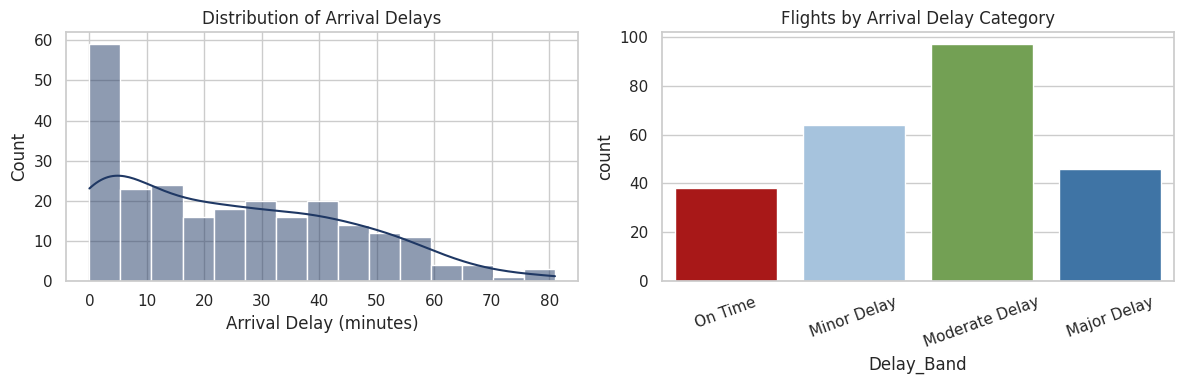

In [7]:
print('Arrival delay summary (minutes):')
print(clean['Arrival_Delay_Min'].describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
delays = clean['Arrival_Delay_Min'].dropna().to_numpy()
counts, bin_edges, _ = ax[0].hist(
    delays, bins=15, color='#1F3864', alpha=0.8, edgecolor='white'
)
# Gaussian KDE, scaled to histogram counts to match the original overlay
if len(delays) > 1:
    bandwidth = max(1.06 * delays.std(ddof=1) * len(delays) ** (-1 / 5), 1e-9)
    x_grid = np.linspace(bin_edges[0], bin_edges[-1], 300)
    density = np.exp(-0.5 * ((x_grid[:, None] - delays[None, :]) / bandwidth) ** 2).sum(axis=1)
    density /= len(delays) * bandwidth * np.sqrt(2 * np.pi)
    ax[0].plot(x_grid, density * len(delays) * (bin_edges[1] - bin_edges[0]), color='#C00000')
ax[0].set_title('Distribution of Arrival Delays')
ax[0].set_xlabel('Arrival Delay (minutes)')

delay_order = ['On Time', 'Minor Delay', 'Moderate Delay', 'Major Delay']
band_counts = clean['Delay_Band'].value_counts().reindex(delay_order, fill_value=0)
band_colors = ['#70AD47', '#9DC3E6', '#2E75B6', '#C00000']
ax[1].bar(delay_order, band_counts.values, color=band_colors)
ax[1].set_title('Flights by Arrival Delay Category')
ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()


### Q2. How are departure delays related to arrival delays and weather impact?

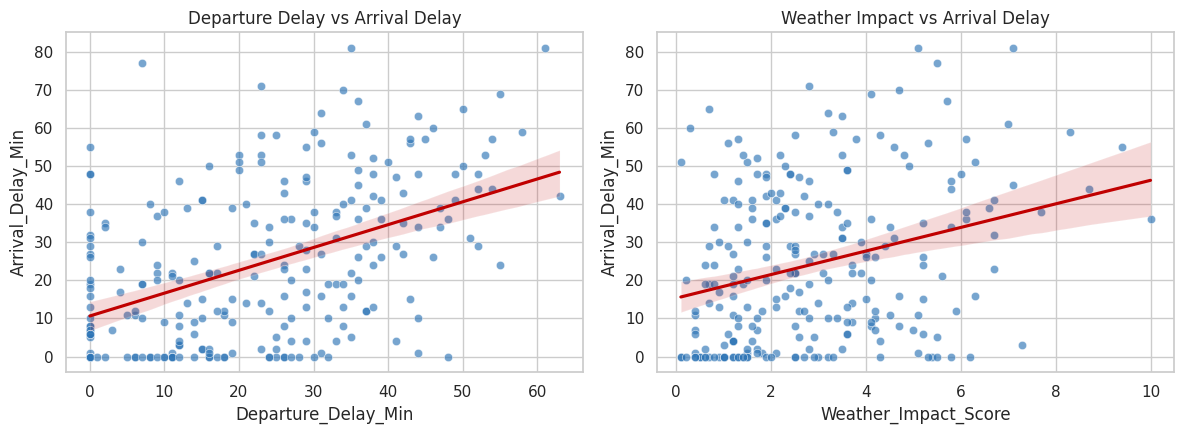

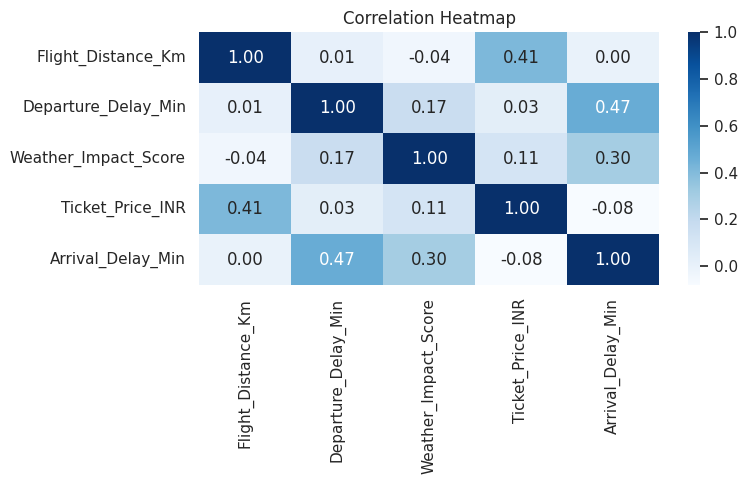

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

for axis, x_col, title in [
    (ax[0], 'Departure_Delay_Min', 'Departure Delay vs Arrival Delay'),
    (ax[1], 'Weather_Impact_Score', 'Weather Impact vs Arrival Delay'),
]:
    x = clean[x_col].to_numpy(dtype=float)
    y = clean['Arrival_Delay_Min'].to_numpy(dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    axis.scatter(x[valid], y[valid], alpha=.65, color='#2E75B6')
    if valid.sum() >= 2 and np.ptp(x[valid]) > 0:
        slope, intercept = np.polyfit(x[valid], y[valid], 1)
        line_x = np.linspace(x[valid].min(), x[valid].max(), 200)
        axis.plot(line_x, slope * line_x + intercept, color='#C00000')
    axis.set_title(title)

plt.tight_layout()
plt.show()

corr_cols = [
    'Flight_Distance_Km', 'Departure_Delay_Min',
    'Weather_Impact_Score', 'Ticket_Price_INR',
    'Arrival_Delay_Min'
]
corr = clean[corr_cols].corr().round(2)
fig, ax = plt.subplots(figsize=(8, 5))
image = ax.imshow(corr, cmap='Blues', vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(corr_cols)), labels=corr_cols, rotation=45, ha='right')
ax.set_yticks(np.arange(len(corr_cols)), labels=corr_cols)
for row in range(len(corr_cols)):
    for col in range(len(corr_cols)):
        ax.text(col, row, f'{corr.iloc[row, col]:.2f}', ha='center', va='center')
fig.colorbar(image, ax=ax)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


In [9]:
print('Correlation with arrival delay:')
print(clean[corr_cols].corr()['Arrival_Delay_Min'].sort_values(ascending=False).round(2))

Correlation with arrival delay:
Arrival_Delay_Min       1.00
Departure_Delay_Min     0.47
Weather_Impact_Score    0.30
Flight_Distance_Km      0.00
Ticket_Price_INR       -0.08
Name: Arrival_Delay_Min, dtype: float64


### Q3. Do delays and ticket prices differ by airline type, cabin class or route?

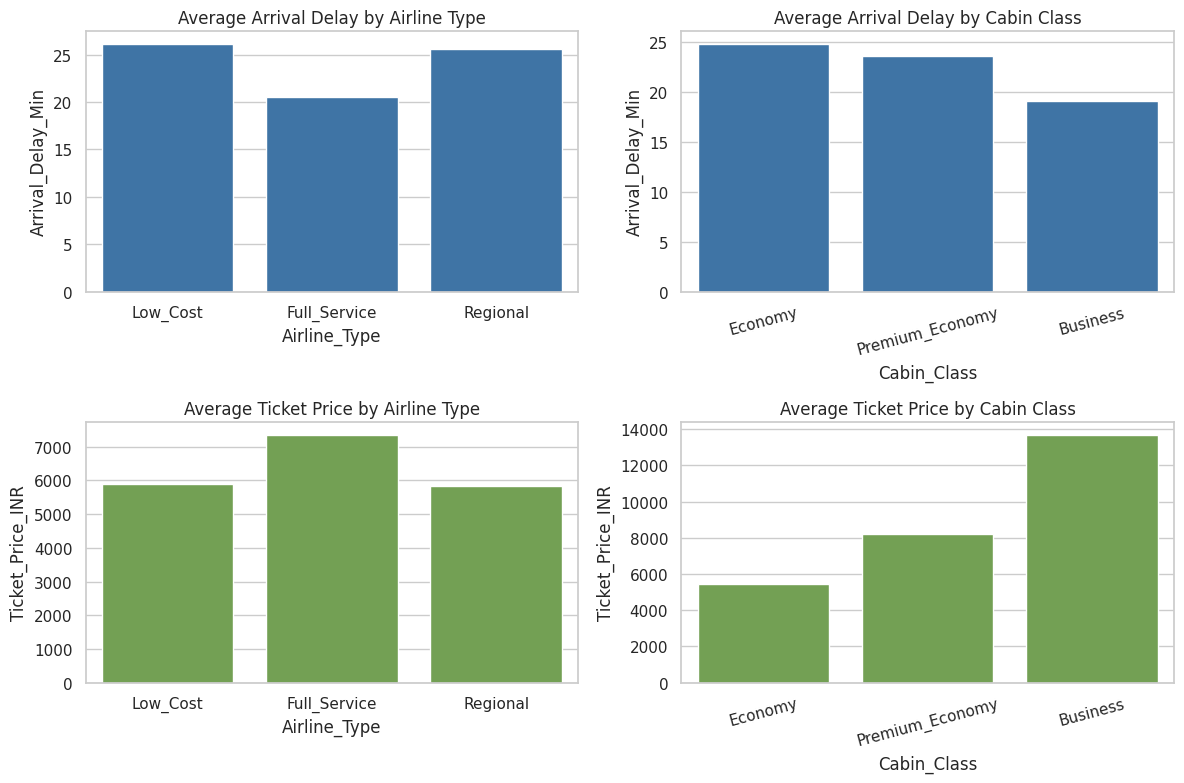

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

plots = [
    ('Airline_Type', 'Arrival_Delay_Min', '#2E75B6', 'Average Arrival Delay by Airline Type', ax[0, 0], 0),
    ('Cabin_Class', 'Arrival_Delay_Min', '#2E75B6', 'Average Arrival Delay by Cabin Class', ax[0, 1], 15),
    ('Airline_Type', 'Ticket_Price_INR', '#70AD47', 'Average Ticket Price by Airline Type', ax[1, 0], 0),
    ('Cabin_Class', 'Ticket_Price_INR', '#70AD47', 'Average Ticket Price by Cabin Class', ax[1, 1], 15),
]
for category, value, color, title, axis, rotation in plots:
    means = clean.groupby(category, observed=False)[value].mean()
    axis.bar(means.index.astype(str), means.values, color=color)
    axis.set_title(title)
    axis.tick_params(axis='x', rotation=rotation)

plt.tight_layout()
plt.show()


### Q4. Which routes and flights show the largest delays?

In [11]:
clean['Route'] = clean['Origin_City'] + ' → ' + clean['Destination_City']

route_delay = (
    clean.groupby('Route')['Arrival_Delay_Min']
    .agg(['count', 'mean'])
    .sort_values('mean', ascending=False)
)
print('Routes with the highest average arrival delay:')
display(route_delay.head(10).round(1))

print('\\nFlights with the largest arrival delays:')
display(
    clean.sort_values('Arrival_Delay_Min', ascending=False)[
        ['Flight_ID', 'Route', 'Airline_Type', 'Arrival_Delay_Min',
         'Departure_Delay_Min', 'Flight_Date']
    ].head(10)
)

Routes with the highest average arrival delay:


,count,mean
Route,,
Kolkata → Hyderabad,2,39.5
Delhi → Delhi,2,32.0
Delhi → Mumbai,19,31.8
Delhi → Bengaluru,15,29.9
Hyderabad → Mumbai,14,25.9
Mumbai → Bengaluru,12,25.8
Delhi → Kolkata,22,25.5
Bengaluru → Hyderabad,12,25.1
Mumbai → Delhi,14,25.1


\nFlights with the largest arrival delays:


,Flight_ID,Route,Airline_Type,Arrival_Delay_Min,Departure_Delay_Min,Flight_Date
61,F1008,Delhi → Mumbai,Full_Service,81,61,2026-06-05
66,F1056,Delhi → Mumbai,Low_Cost,81,35,2025-08-13
135,F1077,Kolkata → Bengaluru,Low_Cost,77,7,2025-06-17
235,F1011,Hyderabad → Mumbai,Low_Cost,71,23,2026-04-28
54,F1018,Hyderabad → Mumbai,Full_Service,70,34,2026-04-16
122,F1082,Delhi → Mumbai,Low_Cost,69,55,2025-06-19
126,F1040,Delhi → Kolkata,Low_Cost,67,36,2026-02-05
143,F1141,Hyderabad → Bengaluru,Low_Cost,65,50,2025-07-12
159,F1062,Bengaluru → Hyderabad,Low_Cost,64,31,2025-06-05
161,F1072,Mumbai → Hyderabad,Low_Cost,63,44,2026-04-27


## 7. Key insights (generated from the data)

In [12]:
avg_arrival = clean['Arrival_Delay_Min'].mean()
median_arrival = clean['Arrival_Delay_Min'].median()
departure_corr = clean['Departure_Delay_Min'].corr(clean['Arrival_Delay_Min'])
weather_corr = clean['Weather_Impact_Score'].corr(clean['Arrival_Delay_Min'])
most_delayed_route = route_delay.index[0]
least_delayed_route = route_delay.index[-1]
airline_delay = clean.groupby('Airline_Type')['Arrival_Delay_Min'].mean()
cabin_price = clean.groupby('Cabin_Class')['Ticket_Price_INR'].mean()

print(f'1. Average arrival delay: {avg_arrival:.1f} minutes; median: {median_arrival:.1f} minutes.')
print(f'2. Departure delay vs arrival delay correlation = {departure_corr:.2f}.')
print(f'3. Weather impact vs arrival delay correlation = {weather_corr:.2f}.')
print(f'4. Route with highest average arrival delay: {most_delayed_route} ({route_delay.iloc[0]["mean"]:.1f} minutes).')
print(f'5. Route with lowest average arrival delay: {least_delayed_route} ({route_delay.iloc[-1]["mean"]:.1f} minutes).')
print('6. Average arrival delay by airline type (minutes):')
print(airline_delay.round(1).to_string())
print('7. Average ticket price by cabin class (INR):')
print(cabin_price.round(0).to_string())

1. Average arrival delay: 24.3 minutes; median: 22.0 minutes.
2. Departure delay vs arrival delay correlation = 0.47.
3. Weather impact vs arrival delay correlation = 0.30.
4. Route with highest average arrival delay: Kolkata → Hyderabad (39.5 minutes).
5. Route with lowest average arrival delay: Bengaluru → Mumbai (16.1 minutes).
6. Average arrival delay by airline type (minutes):
Airline_Type
Full_Service    20.6
Low_Cost        26.2
Regional        25.6
7. Average ticket price by cabin class (INR):
Cabin_Class
Business           13694.0
Economy             5452.0
Premium_Economy     8217.0


## 8. Recommendations
- Review routes with consistently high average arrival delays and investigate operational causes.
- Monitor departure delays because they may be associated with arrival delays.
- Compare weather-impact patterns with delay records when planning schedules.
- Review ticket prices by cabin class and airline type to understand pricing differences.

> **Remember:** correlation does not prove causation. This analysis shows associations in a synthetic practice dataset, not proof that one factor causes another.

## 9. Save the cleaned data

In [13]:
# Save the cleaned and feature-engineered dataset in the notebook's folder
clean.to_csv('airline_flights_data_cleaned.csv', index=False)
print('Saved cleaned file with', len(clean), 'rows.')

Saved cleaned file with 245 rows.
